# News Article Topic Classifier: Random Forest vs. Logistic Regression vs. BERT

Three models are trained on the **same AG News training rows**, tuned only on a **separate validation split**, and compared on the untouched **7,600-article test set**.

| Model | Text representation | Notes |
|---|---|---|
| Logistic Regression | TF-IDF (1-2 grams) on cleaned text | Linear baseline, C tuned on validation set |
| Random Forest | Same TF-IDF features | Tree ensemble on sparse features |
| BERT (`bert-base-uncased`) | WordPiece tokens of lightly cleaned raw text | Fine-tuned end to end, **needs a GPU** (e.g. free Colab T4) |

**Run order:** run everything top to bottom. If you have no GPU yet, set `RUN_BERT = False` in the config cell to get the two classical models first, then switch it on later.

## 1. Setup and configuration

In [ ]:
# Colab only: uncomment and run once, then restart the runtime if asked.
# %pip install -q -U transformers accelerate

In [ ]:
import re, time, json, html, warnings
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, f1_score)
from scipy.stats import binomtest

import nltk
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import joblib

# ---------------- configuration ----------------
RANDOM_STATE = 42
DATA_DIR = "."                 # folder containing train.csv and test.csv
VAL_FRACTION = 0.05            # taken from the training file; used for tuning / model selection only

RUN_BERT = True                # set False to run only the classical models
BERT_MODEL = "bert-base-uncased"
MAX_LEN = 128                  # AG News articles are short; this rarely truncates
BATCH_SIZE = 32
EPOCHS = 2
BERT_LR = 2e-5
BERT_TRAIN_SUBSET = None       # e.g. 30000 for a quick trial; None = full training split (fair comparison)

RF_TREES = 150
# ------------------------------------------------

np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")
try:
    import torch
    torch.manual_seed(RANDOM_STATE)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch, DEVICE = None, "cpu"
print("Device:", DEVICE)
if RUN_BERT and DEVICE == "cpu":
    print("WARNING: no GPU found. Fine-tuning BERT on CPU will take many hours. "
          "Use a GPU runtime or set BERT_TRAIN_SUBSET to a small number.")

Device: cuda


## 2. Dataset
AG News (Kaggle copy of the standard corpus): https://www.kaggle.com/datasets/amananandrai/ag-news-classification-dataset  
Place `train.csv` and `test.csv` in `DATA_DIR`. Labels are converted to 0-3 so that all three models share one label scheme.

In [ ]:
train = pd.read_csv(f"train.csv")
test = pd.read_csv(f"test.csv")
train.columns = ["class_index", "title", "description"]
test.columns = ["class_index", "title", "description"]

LABELS = ["World", "Sports", "Business", "Sci/Tech"]      # index = class_index - 1
for df in (train, test):
    df["text"] = df["title"].astype(str) + " " + df["description"].astype(str)
    df["label"] = df["class_index"] - 1
    df["topic"] = df["label"].map(dict(enumerate(LABELS)))

print("Train:", train.shape, "| Test:", test.shape)
train.head()

Train: (120000, 6) | Test: (7600, 6)


,class_index,title,description,text,label,topic
0,3,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli...",Wall St. Bears Claw Back Into the Black (Reute...,2,Business
1,3,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...,Carlyle Looks Toward Commercial Aerospace (Reu...,2,Business
2,3,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...,Oil and Economy Cloud Stocks' Outlook (Reuters...,2,Business
3,3,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...,Iraq Halts Oil Exports from Main Southern Pipe...,2,Business
4,3,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco...","Oil prices soar to all-time record, posing new...",2,Business


## 3. Exploratory data analysis

Missing values:
 class_index    0
title          0
description    0
text           0
label          0
topic          0
dtype: int64 

Duplicate rows: 0 

Train class counts:
 topic
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64 

Test class counts:
 topic
Business    1900
Sci/Tech    1900
Sports      1900
World       1900
Name: count, dtype: int64


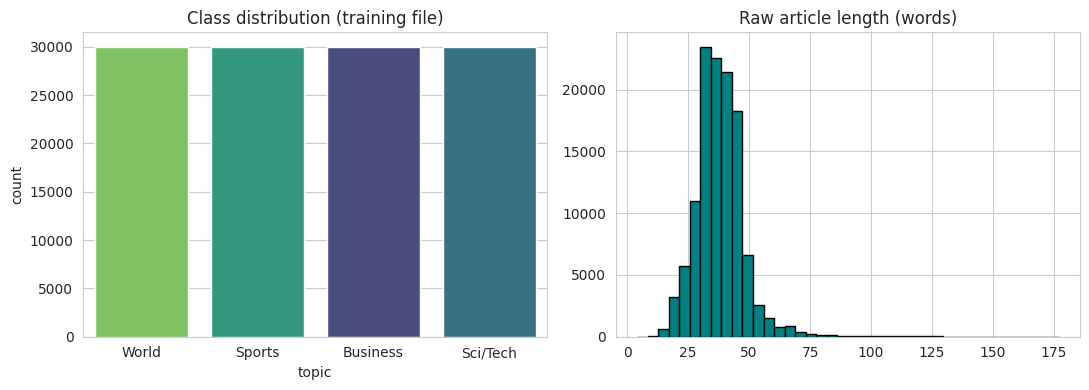

count    120000.000000
mean         37.844617
std          10.088702
min           4.000000
25%          32.000000
50%          37.000000
75%          43.000000
max         177.000000
Name: text_len, dtype: float64


In [ ]:
print("Missing values:\n", train.isnull().sum(), "\n")
print("Duplicate rows:", train.duplicated().sum(), "\n")
print("Train class counts:\n", train["topic"].value_counts(), "\n")
print("Test class counts:\n", test["topic"].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=train, x="topic", hue="topic", order=LABELS, palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Class distribution (training file)")
train["text_len"] = train["text"].str.split().str.len()
axes[1].hist(train["text_len"], bins=40, color="teal", edgecolor="black")
axes[1].set_title("Raw article length (words)")
plt.tight_layout(); plt.show()
print(train["text_len"].describe())

## 4. Text preprocessing

Two representations are needed because the models read text differently:

* **`basic_clean`** (used for BERT): decode HTML entities, remove tags, fix AG News artefacts, normalise spaces. Case, punctuation and stop words are kept because BERT uses them as context.
* **`clean_text`** (used for TF-IDF models): `basic_clean`, then lowercase, remove URLs and punctuation, drop stop words, lemmatise.

**Fix over the first version:** the earlier top-words plot showed `39`, `lt`, `gt`, `quot` as frequent tokens. They are leftovers of HTML entities (`&#39;`, `&lt;`, `&gt;`, `&quot;`), and in this Kaggle copy some appear without the leading `&` (for example `#39;`). `fix_entities` handles both forms. Check the top-words plot below to confirm they are gone.

In [ ]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def fix_entities(text):
    text = html.unescape(str(text))
    # entities whose leading '&' was stripped in this dataset copy
    text = re.sub(r"#39;", "'", text)
    text = re.sub(r"\bquot;", '"', text)
    text = re.sub(r"\bamp;", "&", text)
    text = re.sub(r"\blt;", "<", text)
    text = re.sub(r"\bgt;", ">", text)
    return text

def basic_clean(text):
    text = fix_entities(text)
    text = text.replace("\\", " ")                 # AG News uses literal backslashes as line breaks
    text = re.sub(r"<.*?>", " ", text)               # HTML tags
    text = re.sub(r"\s+", " ", text).strip()
    return text

def clean_text(text):
    text = basic_clean(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    tokens = [t for t in text.split() if t not in stop_words and len(t) > 1]
    return " ".join(lemmatizer.lemmatize(t) for t in tokens)

print("RAW:  ", train["text"].iloc[0])
print("BERT: ", basic_clean(train["text"].iloc[0]))
print("TFIDF:", clean_text(train["text"].iloc[0]))

RAW:   Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
BERT:  Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling band of ultra-cynics, are seeing green again.
TFIDF: wall st bear claw back black reuters reuters short seller wall street dwindling band ultra cynic seeing green


Preprocessing done in 30.6s
Mean words raw / cleaned: 37.8 / 25.6


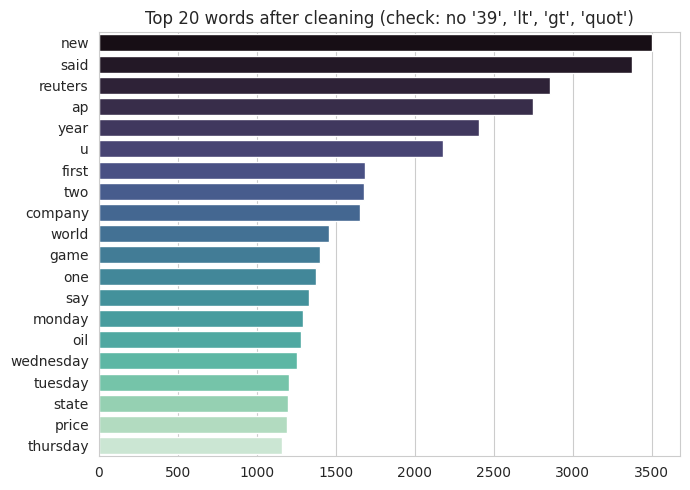

In [ ]:
t0 = time.time()
for df in (train, test):
    df["bert_text"] = df["text"].apply(basic_clean)
    df["clean_text"] = df["text"].apply(clean_text)
print(f"Preprocessing done in {time.time() - t0:.1f}s")
print("Mean words raw / cleaned:", round(train["text_len"].mean(), 1),
      "/", round(train["clean_text"].str.split().str.len().mean(), 1))

from collections import Counter
sample = train["clean_text"].sample(min(20000, len(train)), random_state=RANDOM_STATE)
top20 = Counter(" ".join(sample).split()).most_common(20)
w, f = zip(*top20)
plt.figure(figsize=(7, 5))
sns.barplot(x=list(f), y=list(w), hue=list(w), palette="mako", legend=False)
plt.title("Top 20 words after cleaning (check: no '39', 'lt', 'gt', 'quot')")
plt.tight_layout(); plt.show()

## 5. Train / validation / test split

* **Test set:** the 7,600 articles in `test.csv`, never used for tuning.
* **Validation set:** a stratified 5% slice of `train.csv`. Used to pick `C` for Logistic Regression and the best BERT epoch.
* **Training set:** the remaining 95%. **All three models train on exactly these rows.**

In [ ]:
train_df, val_df = train_test_split(train, test_size=VAL_FRACTION, stratify=train["label"],
                                    random_state=RANDOM_STATE)
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)
y_train, y_val, y_test = train_df["label"].values, val_df["label"].values, test["label"].values
print(f"Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test)}")

results, preds_store, proba_store = {}, {}, {}

def evaluate(name, preds, proba, train_time, infer_time):
    acc = accuracy_score(y_test, preds)
    p_m, r_m, f1_m, _ = precision_recall_fscore_support(y_test, preds, average="macro")
    p_w, r_w, f1_w, _ = precision_recall_fscore_support(y_test, preds, average="weighted")
    results[name] = {"accuracy": acc, "precision_macro": p_m, "recall_macro": r_m, "f1_macro": f1_m,
                     "precision_weighted": p_w, "recall_weighted": r_w, "f1_weighted": f1_w,
                     "train_time_sec": train_time, "test_infer_sec": infer_time}
    preds_store[name], proba_store[name] = np.asarray(preds), np.asarray(proba)
    print(f"{name:22s} acc={acc:.4f}  macro-F1={f1_m:.4f}  train={train_time:.1f}s  predict={infer_time:.2f}s")

Train: 114000 | Validation: 6000 | Test: 7600


## 6. Feature extraction for the classical models: TF-IDF
Fitted on the training rows only; validation and test are only transformed (no leakage). BERT does not use this step; it has its own tokenizer and embeddings (Section 9).

In [ ]:
vectorizer = TfidfVectorizer(max_features=30000, ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)
X_train = vectorizer.fit_transform(train_df["clean_text"])
X_val = vectorizer.transform(val_df["clean_text"])
X_test = vectorizer.transform(test["clean_text"])
print("TF-IDF shapes:", X_train.shape, X_val.shape, X_test.shape)

TF-IDF shapes: (114000, 30000) (6000, 30000) (7600, 30000)


## 7. Model 1: Logistic Regression
`C` is chosen on the **validation set** by macro-F1.

In [ ]:
lr_candidates = {}
for C in [0.1, 1, 3, 10, 30]:
    t0 = time.time()
    m = LogisticRegression(C=C, max_iter=1000, random_state=RANDOM_STATE).fit(X_train, y_train)
    lr_candidates[C] = (m, time.time() - t0, f1_score(y_val, m.predict(X_val), average="macro"))
    print(f"C={C:<5} validation macro-F1 = {lr_candidates[C][2]:.4f}")

best_C = max(lr_candidates, key=lambda c: lr_candidates[c][2])
best_lr, lr_train_time, _ = lr_candidates[best_C]
print("Selected C =", best_C)

t0 = time.time()
proba = best_lr.predict_proba(X_test); preds = proba.argmax(axis=1)
evaluate("Logistic Regression", preds, proba, lr_train_time, time.time() - t0)

C=0.1   validation macro-F1 = 0.9103
C=1     validation macro-F1 = 0.9262
C=3     validation macro-F1 = 0.9235
C=10    validation macro-F1 = 0.9204
C=30    validation macro-F1 = 0.9150
Selected C = 1
Logistic Regression    acc=0.9163  macro-F1=0.9162  train=8.7s  predict=0.01s


## 8. Model 2: Random Forest
Trained on the same TF-IDF matrix. Each tree sees a random subset of features at every split (`max_features="sqrt"`). This is the slowest classical model and can take several minutes on a small CPU; lower `RF_TREES` in the config cell if needed.

In [ ]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=RF_TREES, max_features="sqrt", n_jobs=-1,
                            random_state=RANDOM_STATE).fit(X_train, y_train)
rf_train_time = time.time() - t0
print("Validation macro-F1:", round(f1_score(y_val, rf.predict(X_val), average="macro"), 4))

t0 = time.time()
proba = rf.predict_proba(X_test); preds = proba.argmax(axis=1)
evaluate("Random Forest", preds, proba, rf_train_time, time.time() - t0)

Validation macro-F1: 0.8965
Random Forest          acc=0.8959  macro-F1=0.8955  train=388.0s  predict=0.72s


## 9. Model 3: BERT (fine-tuned)
`bert-base-uncased` is fine-tuned for 4-way classification on `basic_clean` text. Tokenisation is WordPiece; sequences are padded per batch. The best epoch is chosen on the **validation set**, never on the test set. Requires `transformers >= 4.41` and a GPU.

In [ ]:
if RUN_BERT:
    from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                              TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)
    set_seed(RANDOM_STATE)

    tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL)

    class NewsDataset(torch.utils.data.Dataset):
        def __init__(self, texts, labels):
            self.enc = tokenizer(list(texts), truncation=True, max_length=MAX_LEN)
            self.labels = list(labels)
        def __len__(self):
            return len(self.labels)
        def __getitem__(self, i):
            item = {k: v[i] for k, v in self.enc.items()}
            item["labels"] = int(self.labels[i])
            return item

    bert_train_df = train_df if BERT_TRAIN_SUBSET is None else train_df.sample(BERT_TRAIN_SUBSET, random_state=RANDOM_STATE)
    if BERT_TRAIN_SUBSET is not None:
        print(f"NOTE: BERT trains on {len(bert_train_df)} rows, the other models on {len(train_df)}. "
              "State this in the report; the comparison is then not on identical training data.")

    train_ds = NewsDataset(bert_train_df["bert_text"], bert_train_df["label"])
    val_ds = NewsDataset(val_df["bert_text"], val_df["label"])
    test_ds = NewsDataset(test["bert_text"], test["label"])
    print("Datasets ready:", len(train_ds), len(val_ds), len(test_ds))
else:
    print("RUN_BERT is False: skipping BERT.")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Datasets ready: 114000 6000 7600


In [ ]:
if RUN_BERT:
    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        p = logits.argmax(axis=-1)
        return {"accuracy": accuracy_score(labels, p), "f1_macro": f1_score(labels, p, average="macro")}

    bert = AutoModelForSequenceClassification.from_pretrained(
        BERT_MODEL, num_labels=len(LABELS),
        id2label=dict(enumerate(LABELS)), label2id={l: i for i, l in enumerate(LABELS)})

    # 6% of all training steps as warm-up. An explicit step count works in old and new
    # transformers versions (the 'warmup_ratio' argument was removed in recent releases).
    steps_per_epoch = -(-len(train_ds) // BATCH_SIZE)
    warmup_steps = int(0.06 * steps_per_epoch * EPOCHS)

    args = TrainingArguments(
        output_dir="bert_runs", num_train_epochs=EPOCHS,
        per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=64,
        learning_rate=BERT_LR, weight_decay=0.01, warmup_steps=warmup_steps,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="f1_macro",
        fp16=torch.cuda.is_available(), seed=RANDOM_STATE, report_to="none", logging_steps=200)

    trainer = Trainer(model=bert, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                      data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=compute_metrics)

    t0 = time.time()
    trainer.train()
    bert_train_time = time.time() - t0
    print(f"BERT training time: {bert_train_time/60:.1f} min")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.180451,0.164746,0.942500,0.942427
2,0.121244,0.165496,0.948000,0.948010


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

BERT training time: 18.8 min


In [ ]:
if RUN_BERT:
    t0 = time.time()
    out = trainer.predict(test_ds)
    logits = out.predictions
    proba = np.exp(logits - logits.max(axis=1, keepdims=True))
    proba = proba / proba.sum(axis=1, keepdims=True)
    evaluate("BERT", proba.argmax(axis=1), proba, bert_train_time, time.time() - t0)

    trainer.save_model("bert_ag_news"); tokenizer.save_pretrained("bert_ag_news")
    pd.DataFrame(trainer.state.log_history).to_csv("bert_training_log.csv", index=False)

BERT                   acc=0.9430  macro-F1=0.9431  train=1126.1s  predict=11.16s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 10. Evaluation and comparison

In [ ]:
names = list(results)
for n in names:
    print("=" * 70, "\n", n, "\n", "=" * 70)
    print(classification_report(y_test, preds_store[n], target_names=LABELS, digits=4))

 Logistic Regression 
              precision    recall  f1-score   support

       World     0.9333    0.9063    0.9196      1900
      Sports     0.9569    0.9805    0.9685      1900
    Business     0.8836    0.8832    0.8834      1900
    Sci/Tech     0.8910    0.8953    0.8931      1900

    accuracy                         0.9163      7600
   macro avg     0.9162    0.9163    0.9162      7600
weighted avg     0.9162    0.9163    0.9162      7600

 Random Forest 
              precision    recall  f1-score   support

       World     0.9154    0.8937    0.9044      1900
      Sports     0.9264    0.9732    0.9492      1900
    Business     0.8718    0.8558    0.8637      1900
    Sci/Tech     0.8684    0.8611    0.8647      1900

    accuracy                         0.8959      7600
   macro avg     0.8955    0.8959    0.8955      7600
weighted avg     0.8955    0.8959    0.8955      7600

 BERT 
              precision    recall  f1-score   support

       World     0.9631    0.9

In [ ]:
cols = ["accuracy", "precision_macro", "recall_macro", "f1_macro",
        "precision_weighted", "recall_weighted", "f1_weighted", "train_time_sec", "test_infer_sec"]
results_df = pd.DataFrame(results).T[cols]
results_df.round(4).to_csv("model_comparison.csv")
results_df.round(4)

,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,train_time_sec,test_infer_sec
Logistic Regression,0.9163,0.9162,0.9163,0.9162,0.9162,0.9163,0.9162,8.6569,0.0085
Random Forest,0.8959,0.8955,0.8959,0.8955,0.8955,0.8959,0.8955,388.0467,0.7166
BERT,0.9430,0.9433,0.9430,0.9431,0.9433,0.9430,0.9431,1126.1283,11.1648


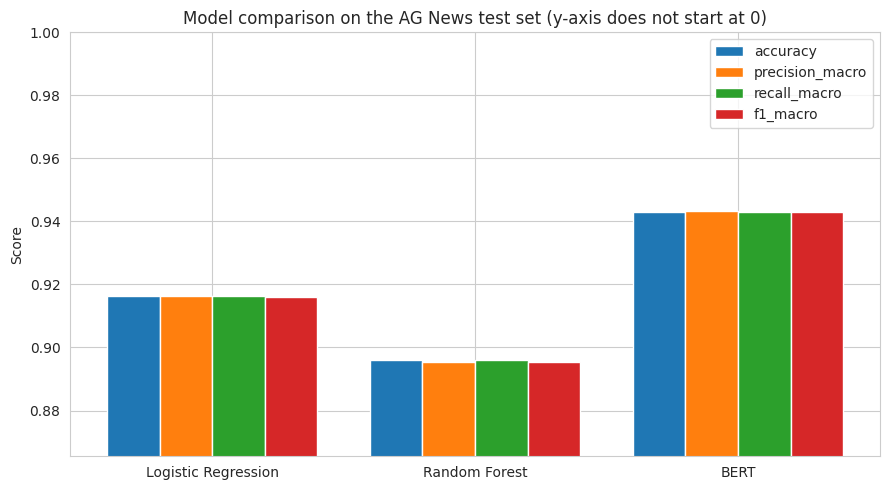

In [ ]:
# Bar chart of the four headline metrics
metrics = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
x, width = np.arange(len(names)), 0.2
plt.figure(figsize=(9, 5))
for i, m in enumerate(metrics):
    plt.bar(x + i * width, [results[n][m] for n in names], width, label=m)
lo = min(results[n][m] for n in names for m in metrics)
plt.ylim(max(0, lo - 0.03), 1.0)
plt.xticks(x + width * 1.5, names); plt.ylabel("Score")
plt.title("Model comparison on the AG News test set (y-axis does not start at 0)")
plt.legend(); plt.tight_layout(); plt.savefig("model_comparison.png", dpi=150); plt.show()

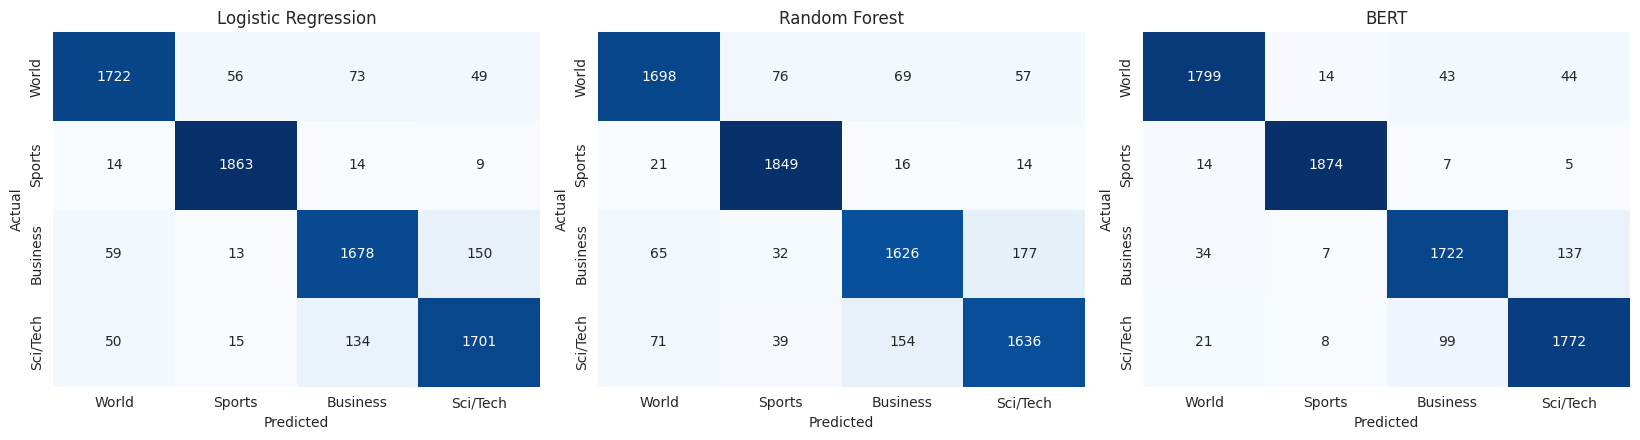

In [ ]:
# Confusion matrices
fig, axes = plt.subplots(1, len(names), figsize=(5.5 * len(names), 4.5))
axes = np.atleast_1d(axes)
for ax, n in zip(axes, names):
    cm = confusion_matrix(y_test, preds_store[n])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=ax, cbar=False)
    ax.set_title(n); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.savefig("confusion_matrices.png", dpi=150); plt.show()

In [ ]:
# Per-class F1 for every model
per_class = pd.DataFrame({n: f1_score(y_test, preds_store[n], average=None) for n in names}, index=LABELS)
print(per_class.round(4))

# How many Business <-> Sci/Tech confusions does each model make?
B, S = LABELS.index("Business"), LABELS.index("Sci/Tech")
conf = {}
for n in names:
    cm = confusion_matrix(y_test, preds_store[n])
    conf[n] = {"Business->Sci/Tech": cm[B, S], "Sci/Tech->Business": cm[S, B],
               "total errors": int((y_test != preds_store[n]).sum())}
pd.DataFrame(conf).T

## 11. Is the difference real?
Results come from one train/test split, so differences of a few tenths of a percent may be noise.

* **Bootstrap 95% interval** for each model's accuracy (resampling the test articles).
* **McNemar's exact test** for each pair of models: it looks only at articles where exactly one of the two is right.

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
correct = {n: (preds_store[n] == y_test) for n in names}

print("Accuracy with bootstrap 95% interval (1000 resamples):")
for n in names:
    boots = [correct[n][rng.integers(0, len(y_test), len(y_test))].mean() for _ in range(1000)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    print(f"  {n:22s} {correct[n].mean():.4f}  [{lo:.4f}, {hi:.4f}]")

def mcnemar_exact(a, b):
    only_a = int((a & ~b).sum()); only_b = int((~a & b).sum()); n = only_a + only_b
    return only_a, only_b, (binomtest(only_a, n, 0.5).pvalue if n else 1.0)

print("\nMcNemar exact test (p < 0.05 suggests a real difference):")
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a_only, b_only, p = mcnemar_exact(correct[names[i]], correct[names[j]])
        print(f"  {names[i]} vs {names[j]}: only first right={a_only}, only second right={b_only}, p={p:.4g}")

## 12. Error analysis
Where do the models disagree, and which articles do all of them get wrong?

In [ ]:
pd.set_option("display.max_colwidth", 150)
test_view = test[["text", "topic"]].copy()
for n in names:
    test_view[n] = [LABELS[i] for i in preds_store[n]]

all_wrong = ~np.any([correct[n] for n in names], axis=0)
print(f"Articles that ALL models misclassify: {all_wrong.sum()} of {len(test)}")
test_view[all_wrong].sample(min(8, all_wrong.sum()), random_state=RANDOM_STATE)

In [ ]:
if "BERT" in names:
    bert_only = correct["BERT"] & ~correct["Logistic Regression"]
    lr_only = ~correct["BERT"] & correct["Logistic Regression"]
    print(f"BERT right, Logistic Regression wrong: {bert_only.sum()}")
    display(test_view[bert_only].sample(min(5, bert_only.sum()), random_state=RANDOM_STATE))
    print(f"Logistic Regression right, BERT wrong: {lr_only.sum()}")
    display(test_view[lr_only].sample(min(5, lr_only.sum()), random_state=RANDOM_STATE))

## 13. Saving the models

In [ ]:
joblib.dump(best_lr, "best_model_logreg.joblib")
joblib.dump(vectorizer, "tfidf_vectorizer.joblib")
joblib.dump(rf, "random_forest.joblib", compress=3)     # can be large even compressed
print("Saved Logistic Regression, TF-IDF vectorizer and Random Forest.")
print("BERT is saved in ./bert_ag_news (if it was trained).")

## 14. Prediction system
`predict_topic` runs one article through all available models and reports each model's topic and confidence. Each model uses its own preprocessing, the same as in training.

In [ ]:
def bert_predict_proba(text):
    enc = tokenizer(basic_clean(text), truncation=True, max_length=MAX_LEN, return_tensors="pt").to(trainer.model.device)
    trainer.model.eval()
    with torch.no_grad():
        return torch.softmax(trainer.model(**enc).logits, dim=-1)[0].cpu().numpy()

def predict_topic(article_text):
    out = {}
    feats = vectorizer.transform([clean_text(article_text)])
    for name, model in [("Logistic Regression", best_lr), ("Random Forest", rf)]:
        p = model.predict_proba(feats)[0]
        out[name] = {"topic": LABELS[int(p.argmax())], "confidence": round(float(p.max()), 4)}
    if RUN_BERT and "BERT" in results:
        p = bert_predict_proba(article_text)
        out["BERT"] = {"topic": LABELS[int(p.argmax())], "confidence": round(float(p.max()), 4)}
    return out

demo = [
    "Apple announced a new generation of processors for its laptop lineup, promising faster performance and better battery life.",
    "The central bank raised interest rates by half a percentage point to curb inflation.",
    "The home team won the championship final in overtime after a dramatic comeback.",
    "Diplomats from several nations met to discuss the ongoing ceasefire negotiations.",
    "Researchers unveiled a new quantum computing chip that could speed up drug discovery.",
]
rows = []
for s in demo:
    r = predict_topic(s)
    rows.append({"article": s[:60] + "...", **{k: f"{v['topic']} ({v['confidence']:.2f})" for k, v in r.items()}})
pd.DataFrame(rows)

## 15. Summary (write your own conclusions here)

After running the notebook, answer these from **your** numbers in `model_comparison.csv`, the confusion matrices and the tests in Section 11:

1. Which model has the highest test accuracy and macro-F1? Is the gap larger than the bootstrap interval and McNemar's test suggest could be noise?
2. What did the accuracy gain (if any) cost in training time and prediction time?
3. Which class is hardest for each model? Did BERT reduce the Business / Sci/Tech confusion?
4. What do the articles that all three models get wrong have in common (label ambiguity, very short text, mixed topics)?
5. Limitations: single split, one seed, BERT hyperparameters not tuned beyond the epoch choice, Random Forest not tuned.